In [1]:
!pip install pandas numpy matplotlib seaborn plotly

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [4]:
from google.colab import files

uploaded = files.upload()

Saving upi_transactions_2024.csv to upi_transactions_2024.csv


In [5]:

df = pd.read_csv("upi_transactions_2024.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (250000, 17)


,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0


In [6]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


Column Names:
['transaction id', 'timestamp', 'transaction type', 'merchant_category', 'amount (INR)', 'transaction_status', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type', 'fraud_flag', 'hour_of_day', 'day_of_week', 'is_weekend']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   transaction id      250000 non-null  object
 1   timestamp           250000 non-null  object
 2   transaction type    250000 non-null  object
 3   merchant_category   250000 non-null  object
 4   amount (INR)        250000 non-null  int64 
 5   transaction_status  250000 non-null  object
 6   sender_age_group    250000 non-null  object
 7   receiver_age_group  250000 non-null  object
 8   sender_state        250000 non-null  object
 9   sender_bank        

In [7]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction id,250000,250000,TXN0000000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,250000,248610,2024-07-23 21:31:06,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction type,250000,4,P2P,112445,NaN,NaN,NaN,NaN,NaN,NaN,NaN
merchant_category,250000,10,Grocery,49966,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount (INR),250000.0,NaN,NaN,NaN,1311.756036,1848.059224,10.0,288.0,629.0,1596.0,42099.0
transaction_status,250000,2,SUCCESS,237624,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sender_age_group,250000,5,26-35,87432,NaN,NaN,NaN,NaN,NaN,NaN,NaN
receiver_age_group,250000,5,26-35,87864,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sender_state,250000,10,Maharashtra,37427,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sender_bank,250000,8,SBI,62693,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
missing_values = df.isnull().sum()
missing_values

,0
transaction id,0
timestamp,0
transaction type,0
merchant_category,0
amount (INR),0
transaction_status,0
sender_age_group,0
receiver_age_group,0
sender_state,0
sender_bank,0


In [12]:
print("Total duplicate rows:", df.duplicated().sum())

print(
    "Duplicate transaction IDs:",
    df['transaction id'].duplicated().sum()
)

Total duplicate rows: 0
Duplicate transaction IDs: 0


In [13]:
df_clean = df.copy()

print("Original shape:", df_clean.shape)

Original shape: (250000, 17)


In [14]:
df_clean['timestamp'] = pd.to_datetime(
    df_clean['timestamp'],
    errors='coerce'
)

print(df_clean['timestamp'].dtype)

datetime64[ns]


In [15]:
# Remove extra spaces from text columns
text_columns = df_clean.select_dtypes(
    include='object'
).columns

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

# Convert amount to numeric
df_clean['amount (INR)'] = pd.to_numeric(
    df_clean['amount (INR)'],
    errors='coerce'
)

# Convert fraud and weekend flags to integers
df_clean['fraud_flag'] = pd.to_numeric(
    df_clean['fraud_flag'],
    errors='coerce'
)

df_clean['is_weekend'] = pd.to_numeric(
    df_clean['is_weekend'],
    errors='coerce'
)

print("Data cleaning completed!")

Data cleaning completed!


In [16]:
print("Invalid timestamps:",
      df_clean['timestamp'].isna().sum())

print("Invalid amounts:",
      df_clean['amount (INR)'].isna().sum())

print("Zero or negative amounts:",
      (df_clean['amount (INR)'] <= 0).sum())

print("Invalid transaction IDs:",
      df_clean['transaction id'].isna().sum())

Invalid timestamps: 0
Invalid amounts: 0
Zero or negative amounts: 0
Invalid transaction IDs: 0


In [17]:
df_clean['year'] = df_clean['timestamp'].dt.year

df_clean['month'] = df_clean['timestamp'].dt.month

df_clean['month_name'] = df_clean['timestamp'].dt.month_name()

df_clean['date'] = df_clean['timestamp'].dt.date

df_clean['hour'] = df_clean['timestamp'].dt.hour

df_clean['quarter'] = df_clean['timestamp'].dt.quarter

df_clean['transaction_amount_category'] = pd.cut(
    df_clean['amount (INR)'],
    bins=[0, 500, 2000, 5000, float('inf')],
    labels=['Low', 'Medium', 'High', 'Very High']
)

df_clean.head()

,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,...,hour_of_day,day_of_week,is_weekend,year,month,month_name,date,hour,quarter,transaction_amount_category
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,...,15,Tuesday,0,2024,10,October,2024-10-08,15,4,Medium
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,...,6,Thursday,0,2024,4,April,2024-04-11,6,2,Medium
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,...,13,Tuesday,0,2024,4,April,2024-04-02,13,2,Low
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,...,10,Sunday,1,2024,1,January,2024-01-07,10,1,High
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,...,19,Tuesday,0,2024,1,January,2024-01-23,19,1,Medium


In [18]:
total_transactions = len(df_clean)

total_amount = df_clean['amount (INR)'].sum()

average_amount = df_clean['amount (INR)'].mean()

successful_transactions = (
    df_clean['transaction_status'] == 'SUCCESS'
).sum()

failed_transactions = (
    df_clean['transaction_status'] == 'FAILED'
).sum()

success_rate = (
    successful_transactions / total_transactions
) * 100

print("Total Transactions:", total_transactions)

print("Total Transaction Value: ₹", total_amount)

print("Average Transaction Value: ₹", round(average_amount, 2))

print("Successful Transactions:", successful_transactions)

print("Failed Transactions:", failed_transactions)

print("Success Rate:", round(success_rate, 2), "%")

Total Transactions: 250000
Total Transaction Value: ₹ 327939009
Average Transaction Value: ₹ 1311.76
Successful Transactions: 237624
Failed Transactions: 12376
Success Rate: 95.05 %


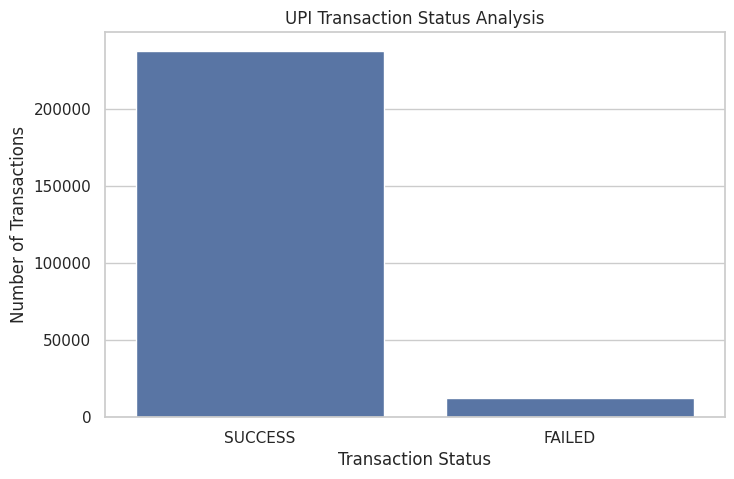

In [19]:
status_counts = df_clean['transaction_status'].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=status_counts.index,
    y=status_counts.values
)

plt.title("UPI Transaction Status Analysis")
plt.xlabel("Transaction Status")
plt.ylabel("Number of Transactions")

plt.show()

In [20]:
state_analysis = (
    df_clean.groupby('sender_state')
    .agg(
        total_transactions=('transaction id', 'count'),
        total_amount=('amount (INR)', 'sum'),
        average_amount=('amount (INR)', 'mean')
    )
    .sort_values(
        by='total_transactions',
        ascending=False
    )
)

state_analysis.head(10)

,total_transactions,total_amount,average_amount
sender_state,,,
Maharashtra,37427,49043948,1310.389505
Uttar Pradesh,30125,40035717,1328.986456
Karnataka,29756,38451158,1292.215284
Tamil Nadu,25367,33343518,1314.444672
Delhi,24870,32689865,1314.429634
Telangana,22435,29750930,1326.094495
Gujarat,20061,25988190,1295.458352
Andhra Pradesh,20006,25952619,1297.241777
Rajasthan,19981,26730470,1337.794405


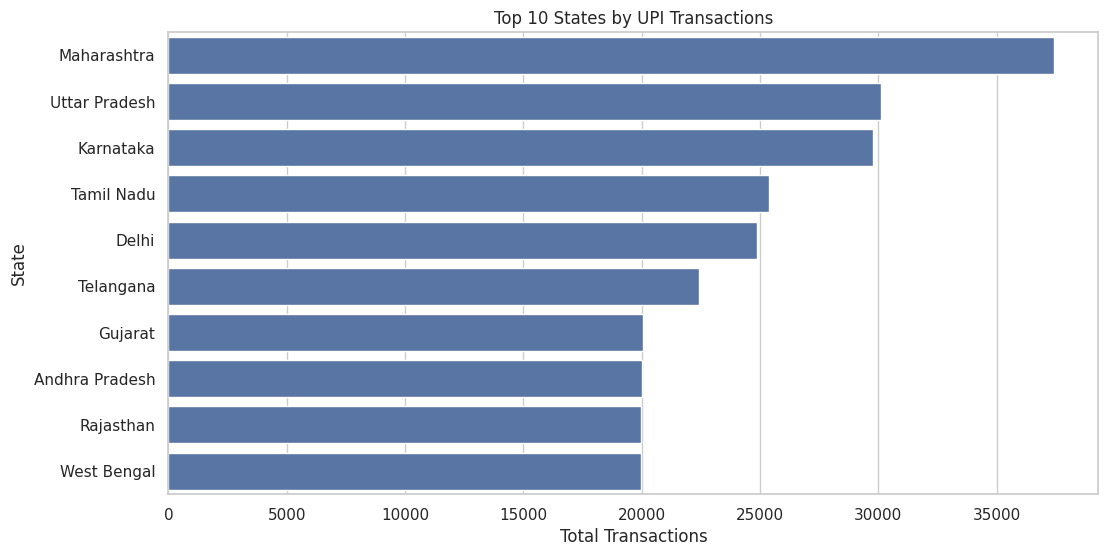

In [21]:
top_states = state_analysis.head(10).reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_states,
    x='total_transactions',
    y='sender_state'
)

plt.title("Top 10 States by UPI Transactions")
plt.xlabel("Total Transactions")
plt.ylabel("State")

plt.show()

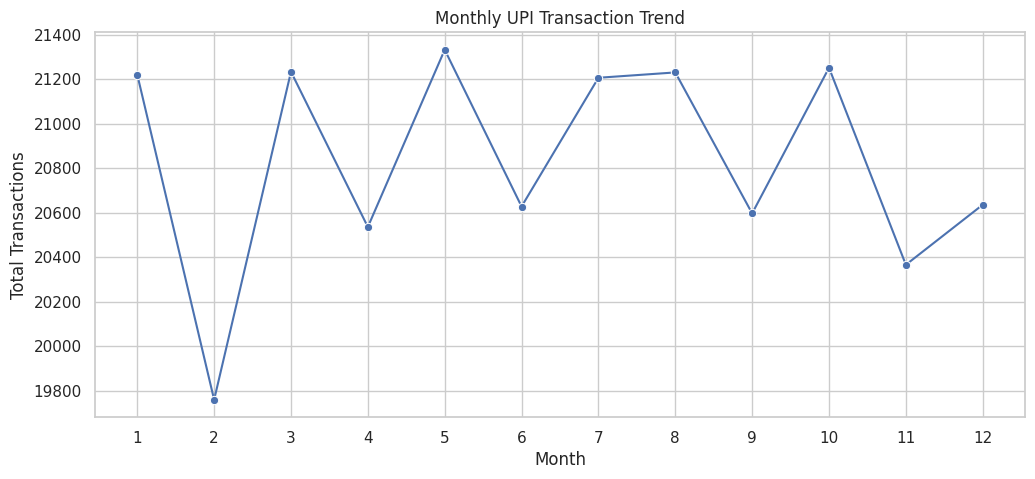

In [22]:
monthly_analysis = (
    df_clean.groupby('month')
    .agg(
        total_transactions=('transaction id', 'count'),
        total_amount=('amount (INR)', 'sum')
    )
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_analysis,
    x='month',
    y='total_transactions',
    marker='o'
)

plt.title("Monthly UPI Transaction Trend")
plt.xlabel("Month")
plt.ylabel("Total Transactions")
plt.xticks(range(1, 13))

plt.show()

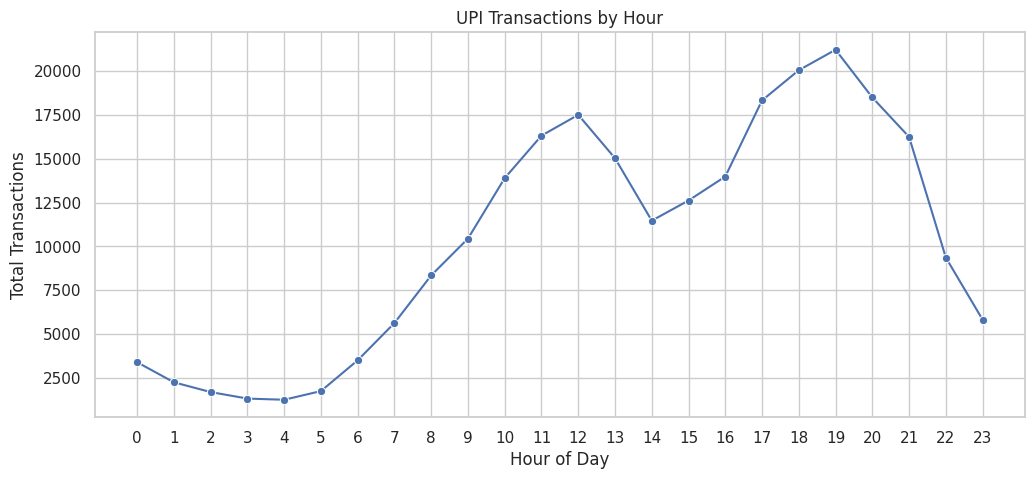

In [23]:
hourly_analysis = (
    df_clean.groupby('hour')
    .size()
    .reset_index(name='total_transactions')
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly_analysis,
    x='hour',
    y='total_transactions',
    marker='o'
)

plt.title("UPI Transactions by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Total Transactions")

plt.xticks(range(0, 24))

plt.show()

Fraud Flag Analysis:
fraud_flag
0    249520
1       480
Name: count, dtype: int64


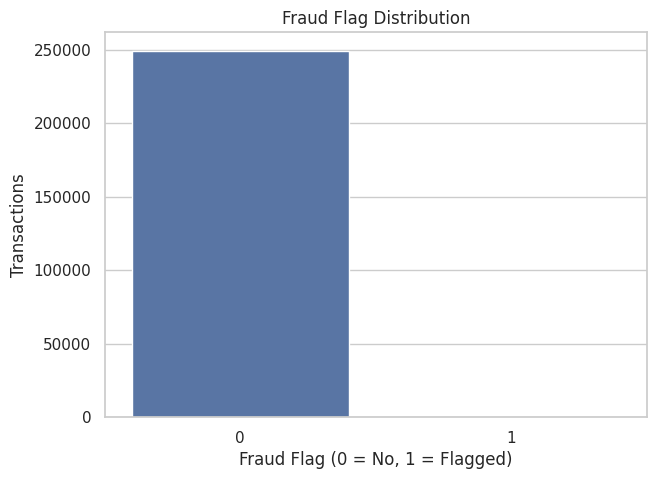

In [24]:
fraud_analysis = df_clean['fraud_flag'].value_counts()

print("Fraud Flag Analysis:")
print(fraud_analysis)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=fraud_analysis.index.astype(str),
    y=fraud_analysis.values
)

plt.title("Fraud Flag Distribution")
plt.xlabel("Fraud Flag (0 = No, 1 = Flagged)")
plt.ylabel("Transactions")

plt.show()

In [25]:
output_file = 'cleaned_upi_transactions.csv'

df_clean.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
from google.colab import files

files.download('cleaned_upi_transactions.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>